In [1]:
import pandas, numpy, scipy

In [2]:
import sklearn, sklearn.preprocessing, sklearn.decomposition

In [3]:
import matplotlib, matplotlib.pyplot
matplotlib.rcParams.update({'font.size':20, 
                            'font.family':'sans-serif', 
                            'xtick.labelsize':16, 
                            'ytick.labelsize':16, 
                            'figure.figsize':(16*(2/3), 9*(2/3)), 
                            'axes.labelsize':20
                           })

# 0. user-defined variables

In [4]:
input_file = '/Users/adrian/research/bmcbf/067_urmia/results/02_bioprint/DESeq2_TPM_values.tsv'

# 1. read expression

In [5]:
expression = pandas.read_csv(input_file, sep='\t', index_col=0)
print(expression.shape)
expression

(39546, 9)


,NT1,NT2,NT3,T251,T252,T253,T501,T502,T503
ENSG00000000003.15,60.564951,35.605355,52.717329,25.256284,38.907441,28.970683,28.965279,26.041029,16.469214
ENSG00000000005.6,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
ENSG00000000419.14,74.850831,67.812030,76.124126,53.783296,69.351428,63.312700,41.899294,37.065104,26.995653
ENSG00000000457.14,12.867233,8.396116,9.701365,6.890270,7.625112,5.927822,4.161594,3.046070,1.705487
ENSG00000000460.17,7.033218,3.205917,3.965620,6.508230,3.062286,2.971540,2.614795,3.918652,0.720946
...,...,...,...,...,...,...,...,...,...
ENSG00000291297.1,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
ENSG00000291298.1,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
ENSG00000291299.1,8.540801,4.026774,5.836038,1.529988,2.379372,1.047746,2.975697,1.145590,0.618863
ENSG00000291300.1,0.083306,0.138637,0.068762,0.072035,0.215792,0.057721,0.000000,0.024969,0.000000


In [6]:
for element in expression.columns:
    print(element)

NT1
NT2
NT3
T251
T252
T253
T501
T502
T503


# 3. filter and transform

In [7]:
substantial_expression = expression[expression.max(axis=1) >= 2]
high_expression = expression[expression.max(axis=1) >= 100]

print(substantial_expression.shape)
print(high_expression.shape)

(14539, 9)
(1680, 9)


In [8]:
transpose = substantial_expression.transpose()
pca_substantial_expression = numpy.log2(transpose + 1)

transpose = high_expression.transpose()
pca_high_expression = numpy.log2(transpose + 1)

# 4. visualize substantial expression

In [9]:
scaled_data = sklearn.preprocessing.StandardScaler().fit_transform(pca_substantial_expression)
model = sklearn.decomposition.PCA(n_components=2)
new = model.fit_transform(scaled_data)
explained = model.explained_variance_ratio_
print(explained)

[0.72612647 0.078313  ]


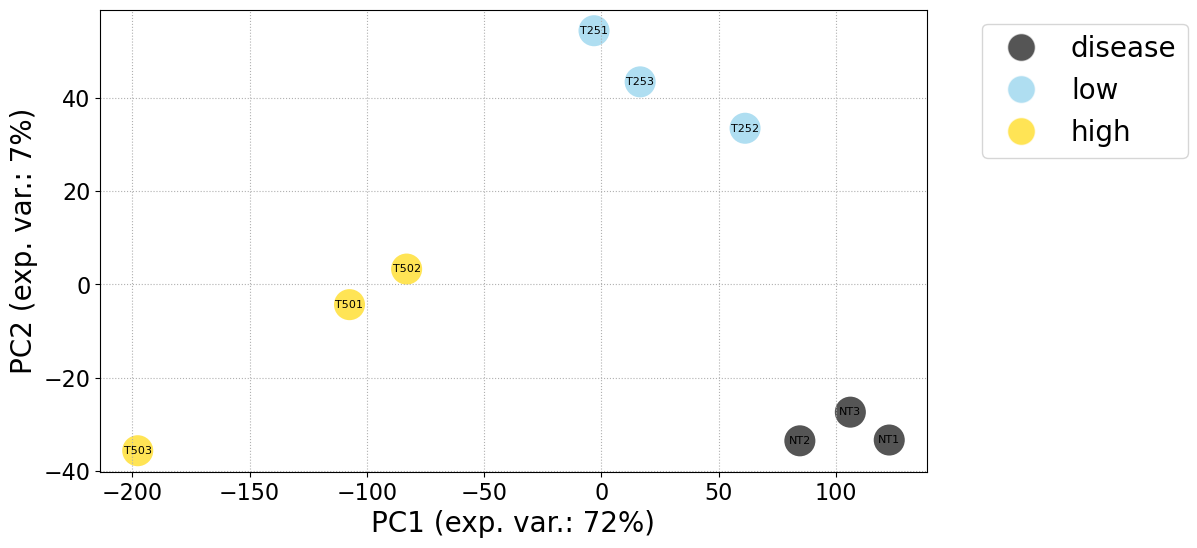

In [10]:
for i in range(len(new)):

    name = expression.columns[i]

    # colors
    if 'NT' in name:
        the_color = 'black'
    elif 'T25' in name:
        the_color = 'skyblue'
    elif 'T50' in name:
        the_color = 'gold'
    else:
        print(name)
        print('error')
        
    matplotlib.pyplot.scatter(new[i,0], new[i,1], s=500, c=the_color, marker='o', alpha=2/3, edgecolors='none')
    epsilon = 0
    matplotlib.pyplot.text(new[i,0]+epsilon, new[i,1]+epsilon, name, size=8, va='center', ha='center')

legend_elements = [
    matplotlib.lines.Line2D([0], [0], color='white', marker='o', markerfacecolor='black', markeredgecolor='white', markersize=20, alpha=2/3),
    matplotlib.lines.Line2D([0], [0], color='white', marker='o', markerfacecolor='skyblue', markeredgecolor='white', markersize=20, alpha=2/3),
    matplotlib.lines.Line2D([0], [0], color='white', marker='o', markerfacecolor='gold', markeredgecolor='white', markersize=20, alpha=2/3)
]

matplotlib.pyplot.legend(legend_elements, ['disease', 'low', 'high'], ncol=1, loc='upper left', bbox_to_anchor=(1.05, 1))

matplotlib.pyplot.xlabel('PC1 (exp. var.: {}%)'.format(int(explained[0]*100)))
matplotlib.pyplot.ylabel('PC2 (exp. var.: {}%)'.format(int(explained[1]*100)))
matplotlib.pyplot.grid(ls=':')

matplotlib.pyplot.show()
#matplotlib.pyplot.savefig('pca.svg')

# 4. visualize high expression

In [11]:
scaled_data = sklearn.preprocessing.StandardScaler().fit_transform(pca_high_expression)
model = sklearn.decomposition.PCA(n_components=2)
new = model.fit_transform(scaled_data)
explained = model.explained_variance_ratio_
print(explained)

[0.82527187 0.08994369]


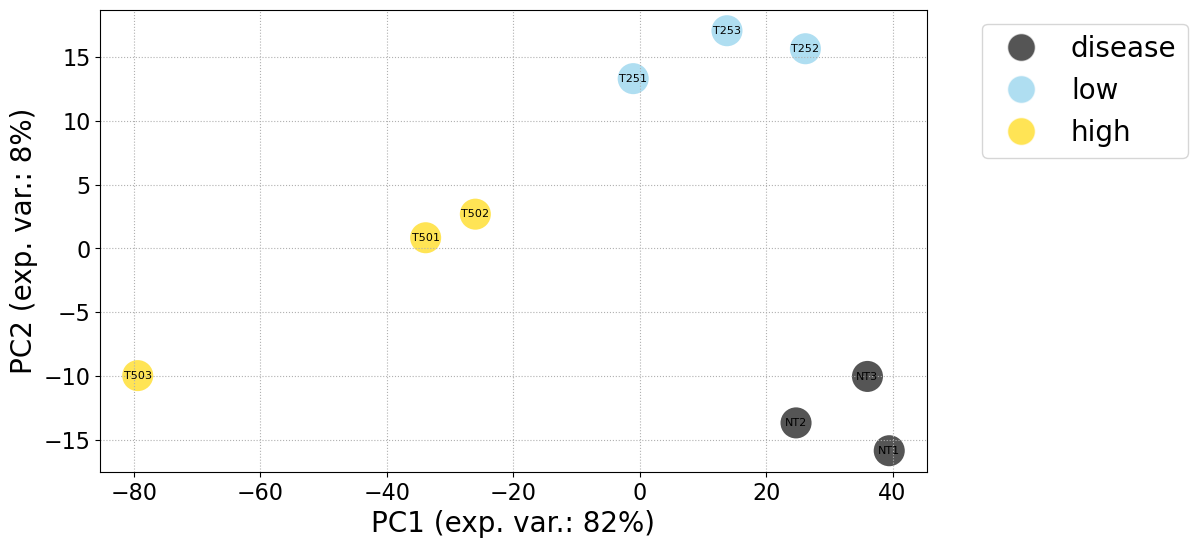

In [12]:
for i in range(len(new)):

    name = expression.columns[i]

    # colors
    if 'NT' in name:
        the_color = 'black'
    elif 'T25' in name:
        the_color = 'skyblue'
    elif 'T50' in name:
        the_color = 'gold'
    else:
        print(name)
        print('error')

        
    matplotlib.pyplot.scatter(new[i,0], new[i,1], s=500, c=the_color, marker='o', alpha=2/3, edgecolors='none')
    epsilon = 0
    matplotlib.pyplot.text(new[i,0]+epsilon, new[i,1]+epsilon, name, size=8, va='center', ha='center')

legend_elements = [
    matplotlib.lines.Line2D([0], [0], color='white', marker='o', markerfacecolor='black', markeredgecolor='white', markersize=20, alpha=2/3),
    matplotlib.lines.Line2D([0], [0], color='white', marker='o', markerfacecolor='skyblue', markeredgecolor='white', markersize=20, alpha=2/3),
    matplotlib.lines.Line2D([0], [0], color='white', marker='o', markerfacecolor='gold', markeredgecolor='white', markersize=20, alpha=2/3)
]

matplotlib.pyplot.legend(legend_elements, ['disease', 'low', 'high'], ncol=1, loc='upper left', bbox_to_anchor=(1.05, 1))

matplotlib.pyplot.xlabel('PC1 (exp. var.: {}%)'.format(int(explained[0]*100)))
matplotlib.pyplot.ylabel('PC2 (exp. var.: {}%)'.format(int(explained[1]*100)))
matplotlib.pyplot.grid(ls=':')

matplotlib.pyplot.show()
#matplotlib.pyplot.savefig('pca.svg')

In [13]:
# 5. distributions

In [14]:
log2_tpm_PO = numpy.log2(expression + 1)
log2_tpm_PO.head()

,NT1,NT2,NT3,T251,T252,T253,T501,T502,T503
ENSG00000000003.15,5.944037,5.193983,5.747316,4.714591,5.318586,4.905480,4.905220,4.757078,4.126743
ENSG00000000005.6,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
ENSG00000000419.14,6.245093,6.104589,6.269110,5.775664,6.136508,6.007032,5.422882,5.250397,4.807131
ENSG00000000457.14,3.793608,3.232065,3.419723,2.980075,3.108543,2.792402,2.367817,2.016521,1.435888
ENSG00000000460.17,3.005978,2.072420,2.311974,2.908473,2.022292,1.989699,1.853914,2.298263,0.783202


167
16.67019429668155


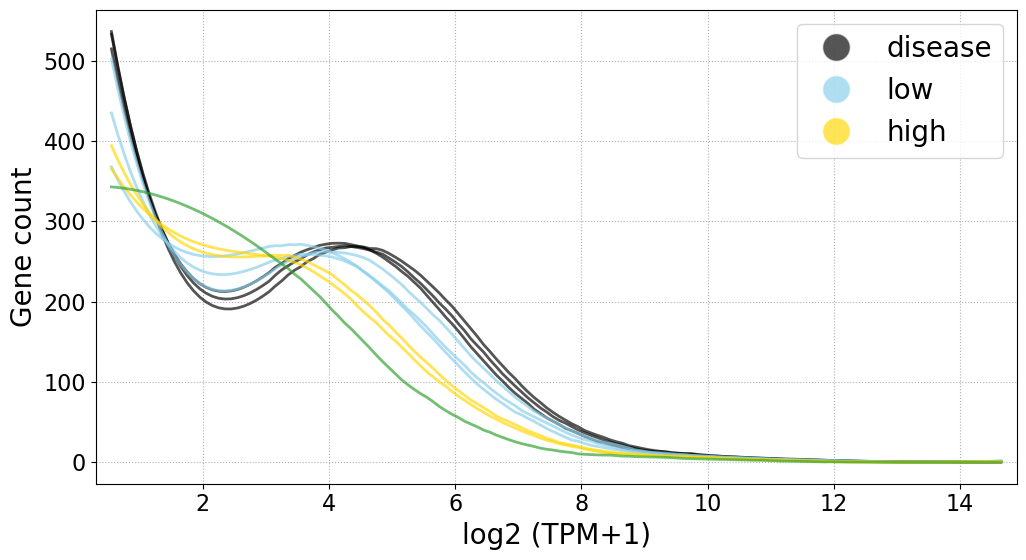

In [17]:
found_max = 16.7
number_of_bins = int(found_max*10)
print(number_of_bins)

absolute_max = 0
working_samples = log2_tpm_PO.columns.to_list()

most_likely_expressions = []
all_hats = []
for i in range(len(working_samples)):

    name = working_samples[i]

    # colors
    if 'NT' in name:
        the_color = 'black'
    elif 'T25' in name:
        the_color = 'skyblue'
    elif 'T50' in name:
        the_color = 'gold'
    else:
        print(name)
        print('error')
    
    log2TPM = log2_tpm_PO.loc[:, name]
    if max(log2TPM) > absolute_max:
        absolute_max = max(log2TPM)
                
    hist, bin_edges = numpy.histogram(log2TPM, bins=number_of_bins, range=(0, found_max))
    half_bin = (bin_edges[1] - bin_edges[0])/2
    x = bin_edges + half_bin
    x = x[:-1]
  
    plotting_x = x[5:-20]
    plotting_hist = hist[5:-20]
    #print(plotting_x)
    
    #matplotlib.pyplot.plot(plotting_x, plotting_hist, 'o', alpha=1/5, mec='none', color=the_color)
    yhat = scipy.signal.savgol_filter(plotting_hist, 51, 3)

    if name == 'T503':
        the_color='tab:green'

    matplotlib.pyplot.plot(plotting_x, yhat, '-', lw=2, alpha=2/3, color=the_color)
    
    
matplotlib.pyplot.xlim([numpy.min(plotting_x)-0.25, numpy.max(plotting_x)+0.25])
#matplotlib.pyplot.ylim([0, 400])

legend_elements = [
    matplotlib.lines.Line2D([0], [0], color='white', marker='o', markerfacecolor='black', markeredgecolor='white', markersize=20, alpha=2/3),
    matplotlib.lines.Line2D([0], [0], color='white', marker='o', markerfacecolor='skyblue', markeredgecolor='white', markersize=20, alpha=2/3),
    matplotlib.lines.Line2D([0], [0], color='white', marker='o', markerfacecolor='gold', markeredgecolor='white', markersize=20, alpha=2/3)
]

matplotlib.pyplot.legend(legend_elements, ['disease', 'low', 'high'], ncol=1, loc='upper right')

matplotlib.pyplot.xlabel('log2 (TPM+1)')
matplotlib.pyplot.ylabel('Gene count')
matplotlib.pyplot.grid(ls=':')

matplotlib.pyplot.tight_layout()

print(absolute_max)